# 01 — Análise exploratória do bootstrap dataset

**Sopro Seguro** · detector de álcool com ESP32 + MQ-3, MQ-135 e DHT11.

Este notebook explora o primeiro conjunto de dados da equipe (o *bootstrap dataset*) e
justifica a preparação dos dados. O roteiro segue o diário da equipe
("Relatório progressão projeto"): cada seção cita a data do diário, mostra os números e
termina com um veredito: **confirmado**, **não confirmado** ou **dados insuficientes**.

Vocabulário:

| Classe | Significado |
| --- | --- |
| `sob_efeito` | bebeu nas condições do experimento (não é laudo nem mg/L) |
| `sem_efeito` | não bebeu: ar limpo, perfume, álcool na mão, borrifo, enxaguante |

Regras que este notebook respeita:

- Só dados da coleta da equipe. Os CSVs de sessão em `esp32-esp8266/` são **lidos, nunca editados**.
  Para rodar o mesmo recorte do `prepare`, os arquivos do lote são copiados para uma pasta temporária.
- Toda a lógica vem de `ml/src/` (validação, recorte de sopro, features). O notebook só orquestra e desenha.
- `ppm` e `alcool` são números do firmware: aparecem aqui só para descrever as sessões
  (o diário fala em PPM), nunca como rótulo ou feature.
- Células marcadas **[EQUIPE: interpretar]** ou **[EQUIPE: decidir]** são da equipe.

Como executar (da raiz do repositório, com o ambiente do `ml` ativo):

```bash
jupyter nbconvert --to notebook --execute --inplace ml/notebooks/01_eda.ipynb
```

As figuras também são gravadas em `ml/reports/figuras_eda/`.

In [1]:
import shutil
import sys
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# O notebook roda de dentro de ml/notebooks; a raiz do ml/ é a pasta de cima.
_cwd = Path.cwd().resolve()
# Aceita rodar de ml/notebooks, de ml/ ou da raiz do repositório.
ML_ROOT = next((p for p in (_cwd.parent, _cwd, _cwd / "ml") if (p / "src" / "features.py").exists()), None)
if ML_ROOT is None:
    raise RuntimeError("rode o notebook de dentro de ml/notebooks, ml/ ou da raiz do repositório")
REPO = ML_ROOT.parent
sys.path.insert(0, str(ML_ROOT))

from src.amostras_sem_efeito import deixar_so_duas_classes, reorganizar_amostras_sem_efeito
from src.data_io import load_raw_data, read_session_csv
from src.data_validation import DataValidationError
from src.features import (
    AFTER_SECONDS,
    BEFORE_SECONDS,
    SENSOR_GROUPS,
    all_feature_columns,
    assign_phases,
    build_dataset,
    compute_features,
)
from src.paths import ProjectPaths
from src.sopros_bebida import PPM_MINIMO, reorganizar_sopros_de_bebida

PASTA_FIRMWARE = REPO / "esp32-esp8266"
LOTE = REPO / "applications" / "dados" / "lote-2026-11.csv"
FIGURAS = ML_ROOT / "reports" / "figuras_eda"
FIGURAS.mkdir(parents=True, exist_ok=True)

# Paleta categórica fixa (slot 1 azul, 2 laranja, 3 verde-água): a cor segue a classe, nunca a ordem.
COR_CLASSE = {"sem_efeito": "#2a78d6", "sob_efeito": "#eb6834"}
COR_CASO = {"clean": "#2a78d6", "drink": "#eb6834", "perfume": "#1baf7a", "outros": "#8a8a85"}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titlesize": 11, "axes.labelsize": 10,
})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)


def salvar(fig, nome: str) -> None:
    """Grava a figura em ml/reports/figuras_eda/<nome>.png."""
    fig.tight_layout()
    fig.savefig(FIGURAS / f"{nome}.png", bbox_inches="tight")

## 0. Fonte dos dados

O firmware grava um CSV por sessão (`leituras_<n>.csv`), copiado para `esp32-esp8266/`.
O manifesto `applications/dados/lote-2026-11.csv` diz quais desses arquivos formam o lote
de treino, com caso (`clean`, `drink`, `perfume`), participante e data no nome da sessão.
Arquivos fora do lote aparecem no inventário, mas **não entram no dataset** do `prepare`.

In [2]:
lote = pd.read_csv(LOTE)
lote["dia"] = lote["sessao"].str.slice(0, 10)
por_origem = lote.set_index("origem")

linhas = []
leituras_brutas = {}
for caminho in sorted(PASTA_FIRMWARE.glob("*.csv")):
    cabecalho = pd.read_csv(caminho, nrows=0).columns
    try:
        df = read_session_csv(caminho)  # valida tipos, ordena por t_ms; não altera o arquivo
        problema = ""
    except DataValidationError as exc:
        df, problema = None, "; ".join(exc.problems)[:80]
    info = por_origem.loc[caminho.name] if caminho.name in por_origem.index else None
    if df is not None:
        leituras_brutas[caminho.name] = df
    linhas.append({
        "arquivo": caminho.name,
        "no_lote": info is not None,
        "caso_lote": info["caso"] if info is not None else "",
        "dia": info["dia"] if info is not None else "sem data",
        "linhas": None if df is None else len(df),
        "minutos": None if df is None else round((df["t_ms"].max() - df["t_ms"].min()) / 60000, 1),
        "colunas_tensao": "tensao_atual_mv" in cabecalho,
        "ppm_max_firmware": None if df is None else df["ppm"].max(),
        "problema": problema,
    })
inventario = pd.DataFrame(linhas)
inventario

,arquivo,no_lote,caso_lote,dia,linhas,minutos,colunas_tensao,ppm_max_firmware,problema
0,leituras.csv,False,,sem data,181,3.3,False,1.3,
1,leituras_11_alcool.csv,True,drink,2026-11-12,81,4.4,True,3.8,
2,leituras_11_alcool2.csv,True,drink,2026-11-12,301,6.1,True,3.8,
3,leituras_14_Alcool3.csv,True,drink,2026-11-12,144,3.0,True,2.1,
4,leituras_17_Alcool.csv,True,drink,2026-11-12,201,4.3,True,1.9,
5,leituras_1_ambiente.csv,True,clean,2026-11-14,153,3.6,True,0.6,
6,leituras_20_sensor_Instavel.csv,False,,sem data,57,1.2,True,1.1,
7,leituras_25_perfume.csv,True,perfume,2026-11-12,102,2.3,True,0.8,
8,leituras_28_ambiente.csv,True,clean,2026-11-14,7784,187.5,True,0.4,
9,leituras_2_ambiente.csv,True,clean,2026-11-14,60,1.5,True,0.5,


`leituras_novos_acima_08.csv` tem uma coluna `sessao`: é um recorte de outros arquivos, não uma
sessão do firmware. `leituras_20_sensor_Instavel.csv` foi marcado pela própria equipe como sensor
instável. Os dois ficam fora de toda análise.

### Montar o dataset como o `prepare` faz

Os 12 arquivos do lote são copiados (com o nome da sessão) para uma pasta temporária, e lá rodam as
mesmas funções de `src/` que o `prepare` usa:

1. `reorganizar_sopros_de_bebida`: nos arquivos de bebida, cada 3 amostras seguidas são um sopro;
   o trio sai se algum PPM fica abaixo de 0,6.
2. `reorganizar_amostras_sem_efeito`: nos outros arquivos, umidade ≥ 60% vira sopro de 3 amostras;
   abaixo disso, cada amostra vira uma linha.
3. `deixar_so_duas_classes`, `load_raw_data`, `assign_phases` (15 s antes, sopro, 30 s depois),
   `compute_features` e `build_dataset`.

Nada é gravado em `ml/data/raw/`.

In [3]:
pasta_tmp = Path(tempfile.mkdtemp(prefix="eda_"))
paths = ProjectPaths(root=pasta_tmp)
paths.raw_sessions_dir.mkdir(parents=True)
for item in lote.itertuples():
    shutil.copyfile(PASTA_FIRMWARE / item.origem, paths.raw_sessions_dir / item.sessao)

avisos = reorganizar_sopros_de_bebida(paths, LOTE)
avisos += reorganizar_amostras_sem_efeito(paths, LOTE)
avisos += deixar_so_duas_classes(paths.raw_attempts)
leituras, tentativas, avisos_carga = load_raw_data(paths.raw_sessions_dir, paths.raw_attempts)
fases, avisos_fase = assign_phases(leituras, tentativas)
features, avisos_feat = compute_features(fases)
dataset = build_dataset(features, tentativas)

# Metadados para a análise (não são features): caso do lote, dia e tipo de linha.
sessao_meta = lote.set_index("sessao")
for tabela in (leituras, tentativas, dataset):
    tabela["caso"] = tabela["session_file"].map(sessao_meta["caso"])
    tabela["dia"] = tabela["session_file"].map(sessao_meta["dia"])
tentativas["tipo"] = np.where(tentativas["notes"].str.contains("3 amostras"), "sopro (3 amostras)", "amostra avulsa")
dataset["tipo"] = dataset["attempt_id"].map(tentativas.set_index("attempt_id")["tipo"])
fases["caso"] = fases["session_file"].map(sessao_meta["caso"])

print(*avisos, sep="\n")
print(f"\n{len(leituras)} leituras, {len(tentativas)} tentativas, {len(dataset)} com features")
print("avisos de recorte:", len(avisos_fase), "| tentativas descartadas:", len(tentativas) - len(dataset))

2026-11-12_equipe_drink_1.csv: 27 sopros de 3 amostras; 0 trios de fora (ppm abaixo de 0.6, ppm vazio ou sem duração)
2026-11-12_equipe_drink_2.csv: 65 sopros de 3 amostras; 35 trios de fora (ppm abaixo de 0.6, ppm vazio ou sem duração)
2026-11-12_equipe_drink_3.csv: 41 sopros de 3 amostras; 7 trios de fora (ppm abaixo de 0.6, ppm vazio ou sem duração)
2026-11-12_equipe_drink_4.csv: 65 sopros de 3 amostras; 2 trios de fora (ppm abaixo de 0.6, ppm vazio ou sem duração)
2026-11-12_equipe_clean_6.csv: 11 sopros de 3 amostras com umidade >= 60.0; 1625 amostras avulsas; classe sem_efeito
2026-11-12_equipe_clean_7.csv: 0 sopros de 3 amostras com umidade >= 60.0; 1339 amostras avulsas; classe sem_efeito
2026-11-12_equipe_perfume_1.csv: 0 sopros de 3 amostras com umidade >= 60.0; 102 amostras avulsas; classe sem_efeito
2026-11-14_equipe_clean_1.csv: 0 sopros de 3 amostras com umidade >= 60.0; 153 amostras avulsas; classe sem_efeito
2026-11-14_equipe_clean_2.csv: 0 sopros de 3 amostras com umid

## 1. Visão geral (diário de 03/11, 12/11 e 13–14/11)

Volume por classe, caso, participante e dia; valores ausentes; e o registro longo de ambiente
que ficou ligado no fim de semana de 13–14/11.

In [4]:
print("Tentativas por classe e tipo de linha:")
display(pd.crosstab(dataset["target"], dataset["tipo"], margins=True))
print("Tentativas por caso, dia e participante:")
display(dataset.groupby(["dia", "caso", "participant_id"]).size().rename("tentativas").to_frame())
print("Participantes distintos:", dataset["participant_id"].nunique(), list(dataset["participant_id"].unique()))
print("Sessões distintas:", dataset["session_file"].nunique())
participacao = dataset["session_file"].value_counts(normalize=True).head(3).round(3)
print("Maior participação de uma sessão no dataset:\n", participacao.to_string())

Tentativas por classe e tipo de linha:


tipo,amostra avulsa,sopro (3 amostras),All
target,,,
sem_efeito,11120,11,11131
sob_efeito,0,194,194
All,11120,205,11325


Tentativas por caso, dia e participante:


tentativas
dia        caso    participant_id            
2026-11-12 clean   equipe                2957
           drink   equipe                 194
           perfume equipe                 100
2026-11-14 clean   equipe                8074

Participantes distintos: 1 ['equipe']
Sessões distintas: 12
Maior participação de uma sessão no dataset:
 session_file
2026-11-14_equipe_clean_5.csv    0.682
2026-11-12_equipe_clean_6.csv    0.144
2026-11-12_equipe_clean_7.csv    0.117


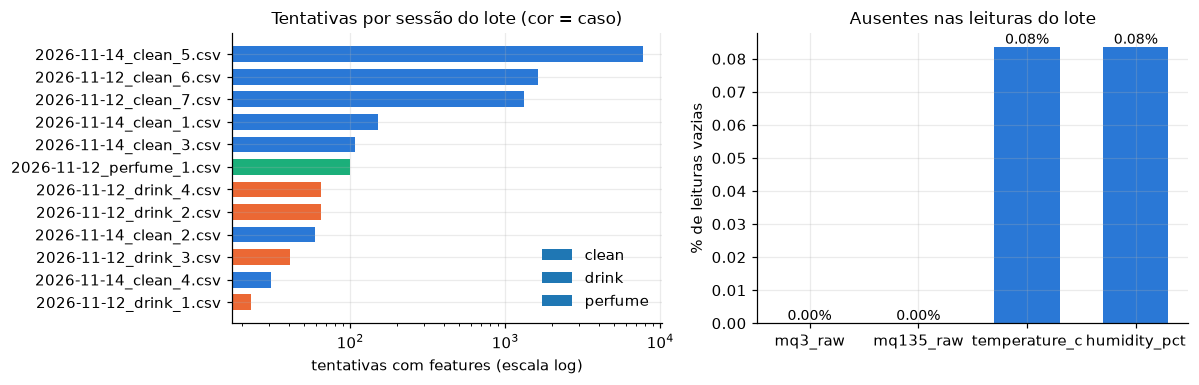

Ausentes nas features (% das tentativas):


,% vazio
humidity_recovery_s,75.5
mq3_recovery_s,14.5
mq135_recovery_s,11.3
mq135_mq3_rise_ratio,0.2
mq3_humidity_peak_lag_s,0.1
humidity_peak_time_s,0.1
humidity_rise,0.1
humidity_peak,0.1
humidity_before,0.1
mq3_before,0.0


In [5]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 3.6))
contagem = dataset.groupby(["session_file", "caso"]).size().reset_index(name="n").sort_values("n")
eixos[0].barh(contagem["session_file"].str.replace("_equipe", ""), contagem["n"],
              color=contagem["caso"].map(COR_CASO), height=0.7)
eixos[0].set_xscale("log")
eixos[0].set_xlabel("tentativas com features (escala log)")
eixos[0].set_title("Tentativas por sessão do lote (cor = caso)")
for caso, cor in COR_CASO.items():
    if caso in set(contagem["caso"]):
        eixos[0].barh([], [], color=cor, label=caso)
eixos[0].legend(frameon=False, loc="lower right")

ausentes = leituras[["mq3_raw", "mq135_raw", "temperature_c", "humidity_pct"]].isna().mean() * 100
eixos[1].bar(ausentes.index, ausentes.values, color="#2a78d6", width=0.6)
for x, v in enumerate(ausentes.values):
    eixos[1].text(x, v, f"{v:.2f}%", ha="center", va="bottom", fontsize=9)
eixos[1].set_ylabel("% de leituras vazias")
eixos[1].set_title("Ausentes nas leituras do lote")
salvar(fig, "01_volume_e_ausentes")
plt.show()

print("Ausentes nas features (% das tentativas):")
display((dataset[all_feature_columns()].isna().mean() * 100).round(1).sort_values(ascending=False).to_frame("% vazio"))

O DHT11 só responde alguns segundos depois da partida, por isso a umidade e a temperatura
começam vazias em cada sessão. Os `*_recovery_s` ficam vazios por definição quando o sensor
não subiu ou não voltou à metade da subida dentro dos 30 s.

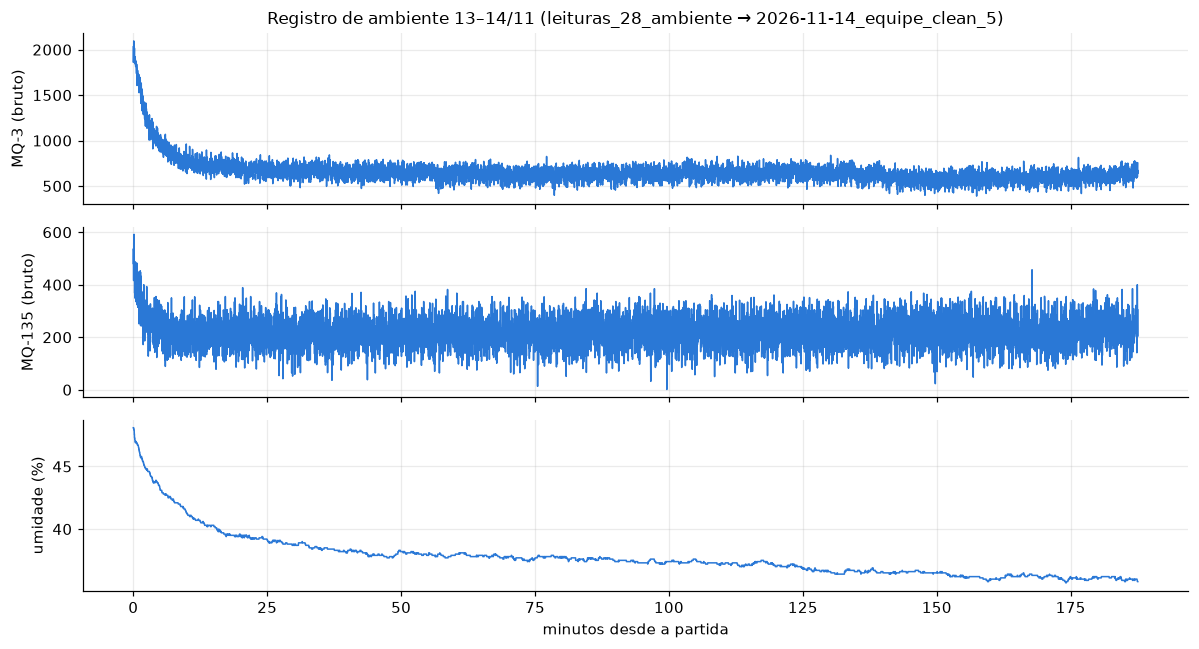

MQ-3 nos 5 primeiros minutos: mediana 1253 (máx 2096); depois: mediana 636, IQR 586–688
duração: 188 min; 7784 leituras


In [6]:
ambiente = leituras[leituras["session_file"] == "2026-11-14_equipe_clean_5.csv"].copy()
ambiente["min"] = (ambiente["t_ms"] - ambiente["t_ms"].min()) / 60000
fig, eixos = plt.subplots(3, 1, figsize=(11, 6), sharex=True)
for eixo, coluna, nome in zip(eixos, ["mq3_raw", "mq135_raw", "humidity_pct"], ["MQ-3 (bruto)", "MQ-135 (bruto)", "umidade (%)"]):
    eixo.plot(ambiente["min"], ambiente[coluna], color="#2a78d6", linewidth=1)
    eixo.set_ylabel(nome)
eixos[0].set_title("Registro de ambiente 13–14/11 (leituras_28_ambiente → 2026-11-14_equipe_clean_5)")
eixos[-1].set_xlabel("minutos desde a partida")
salvar(fig, "01_ambiente_fim_de_semana")
plt.show()

primeiros = ambiente[ambiente["min"] <= 5]["mq3_raw"]
resto = ambiente[ambiente["min"] > 5]["mq3_raw"]
print(f"MQ-3 nos 5 primeiros minutos: mediana {primeiros.median():.0f} (máx {primeiros.max():.0f}); "
      f"depois: mediana {resto.median():.0f}, IQR {resto.quantile(.25):.0f}–{resto.quantile(.75):.0f}")
print(f"duração: {ambiente['min'].max():.0f} min; {len(ambiente)} leituras")

**Veredito — seção 1:** **dados insuficientes** para um modelo que generalize. Há um só
participante (`equipe`), 12 sessões em dois dias, e uma sessão de ambiente responde pela maior
parte das linhas. As classes ficam muito desbalanceadas (ver a primeira tabela). O registro de
13–14/11 cumpre o objetivo do diário: muitas leituras de ar ambiente. Ele também mostra o
aquecimento do MQ-3 nos primeiros minutos.

> **[EQUIPE: interpretar]** _Texto da equipe. Os números acima são a base; o agente não escreve a interpretação._

## 2. Mudança de alimentação em 10/11 (≈3,8 V → ≈4,8 V)

O diário de 10/11 registra que o sensor recebia ≈3,8 V na protoboard antiga e ≈4,8 V depois do
ajuste. Antes, as leituras altas de álcool ficavam entre 0,9 e 2 (PPM do firmware); depois,
chegaram a 12 com álcool 70%.

**Limitação:** nenhum CSV do repositório traz data anterior a 10/11, e o teste com álcool 70% que
chegou a 12 não está entre os arquivos. Como aproximação, separamos os arquivos pelo **esquema
do CSV**: os gravados com as colunas `tensao_atual_mv`/`tensao_referencia_mv` vêm de um firmware
mais novo. Isso é **hipótese**: o lote data `leituras_7_ambiente.csv` de 12/11, e ele não tem
essas colunas. A equipe precisa confirmar quais sessões são de antes do ajuste.

no_lote  mq3_mediana  mq3_p95  ppm_max
grupo                                  arquivo                                                         
com colunas de tensão                  leituras_11_alcool.csv       True       2138.0   3024.0      3.8
                                       leituras_11_alcool2.csv      True       1645.0   2474.0      3.8
                                       leituras_14_Alcool3.csv      True       1560.0   2140.6      2.1
                                       leituras_17_Alcool.csv       True       2041.0   2350.0      1.9
                                       leituras_1_ambiente.csv      True        638.0    752.8      0.6
                                       leituras_25_perfume.csv      True       2241.5   2835.8      0.8
                                       leituras_28_ambiente.csv     True        640.0    813.0      0.4
                                       leituras_2_ambiente.csv      True        628.0    714.8      0.5
                                       leituras_3_ambiente.csv      True        627.5    708.1      0.5
                                       leituras_4_ambiente.csv      True        668.0    765.2      0.5
                                       leituras_9_ambiente.csv      True        930.0   1238.1      1.2
sem colunas de tensão (provável antes) leituras.csv                False       1193.0   2097.0      1.3
                                       leituras_7_ambiente.csv      True       1322.0   2832.3      2.6
                                       leituras_ambiente.csv       False       2227.0   2274.0      0.4
                                       leituras_bebida1.csv        False       1983.5   2102.8      0.6
                                       leituras_bebida2.csv        False       1749.0   1857.6      0.5
                                       leituras_bebida3.csv        False       1759.0   1904.5      0.5
                                       leituras_conversa1.csv      False       1856.0   1950.9      0.5
                                       leituras_listerine.csv      False       1808.0   1849.8      0.4
                                       leituras_perfume.csv        False       2158.0   2207.0      0.7

/var/folders/xx/kdcw5xsx36q893nwf6wrr49m0000gn/T/ipykernel_42915/2395219304.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  caixa = eixo.boxplot(dados, vert=False, patch_artist=True, showfliers=False, widths=0.6)


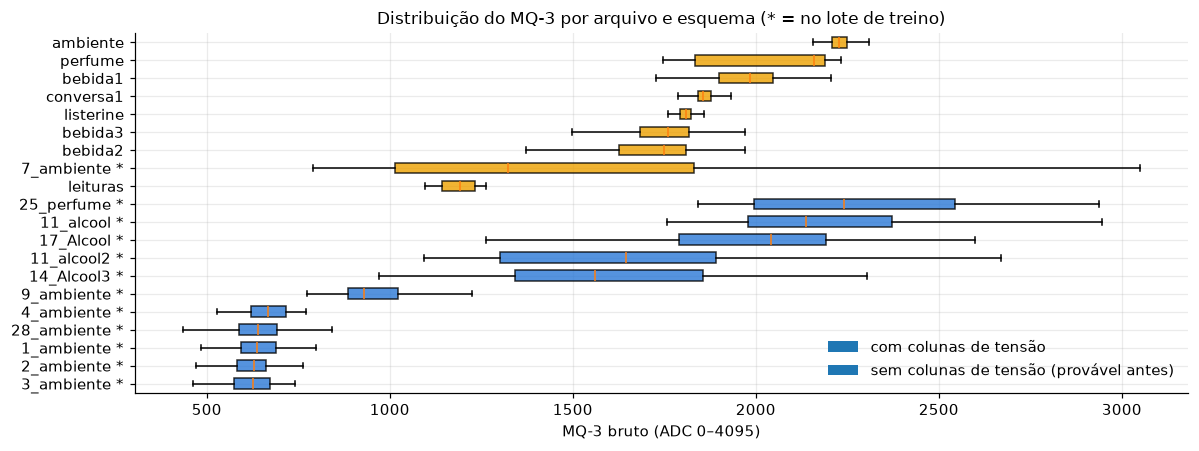

PPM máximo do firmware por grupo:


grupo
com colunas de tensão                     3.8
sem colunas de tensão (provável antes)    2.6
Name: ppm, dtype: float64

In [7]:
excluir = {"leituras_novos_acima_08.csv", "leituras_20_sensor_Instavel.csv"}
blocos = []
for nome, df in leituras_brutas.items():
    if nome in excluir:
        continue
    info = inventario.set_index("arquivo").loc[nome]
    blocos.append(pd.DataFrame({
        "arquivo": nome,
        "grupo": "com colunas de tensão" if info["colunas_tensao"] else "sem colunas de tensão (provável antes)",
        "no_lote": info["no_lote"],
        "mq3_raw": df["mq3_raw"],
        "ppm": df["ppm"],
    }))
por_arquivo = pd.concat(blocos, ignore_index=True)

resumo_grupo = por_arquivo.groupby(["grupo", "arquivo"]).agg(
    no_lote=("no_lote", "first"),
    mq3_mediana=("mq3_raw", "median"),
    mq3_p95=("mq3_raw", lambda s: s.quantile(0.95)),
    ppm_max=("ppm", "max"),
).round(1)
display(resumo_grupo)

fig, eixo = plt.subplots(figsize=(11, 4.2))
ordem = resumo_grupo.reset_index().sort_values(["grupo", "mq3_mediana"])
cores = {"com colunas de tensão": "#2a78d6", "sem colunas de tensão (provável antes)": "#eda100"}
dados = [por_arquivo.loc[por_arquivo["arquivo"] == a, "mq3_raw"] for a in ordem["arquivo"]]
caixa = eixo.boxplot(dados, vert=False, patch_artist=True, showfliers=False, widths=0.6)
for patch, grupo in zip(caixa["boxes"], ordem["grupo"]):
    patch.set_facecolor(cores[grupo])
    patch.set_alpha(0.8)
eixo.set_yticks(range(1, len(ordem) + 1), [a.replace("leituras_", "").replace(".csv", "") + (" *" if l else "") for a, l in zip(ordem["arquivo"], ordem["no_lote"])])
for grupo, cor in cores.items():
    eixo.barh([], [], color=cor, label=grupo)
eixo.legend(frameon=False, loc="lower right")
eixo.set_xlabel("MQ-3 bruto (ADC 0–4095)")
eixo.set_title("Distribuição do MQ-3 por arquivo e esquema (* = no lote de treino)")
salvar(fig, "02_mq3_por_esquema")
plt.show()

print("PPM máximo do firmware por grupo:")
display(por_arquivo.groupby("grupo")["ppm"].max())

**Decisão da equipe sobre as sessões antigas** **[EQUIPE: decidir]**

Opções: `"incluir"` (usar tudo junto), `"excluir"` (tirar do dataset as sessões de antes do
ajuste) ou `"marcar"` (manter e criar uma coluna `periodo` para avaliar o efeito). O padrão
abaixo é `"marcar"`, que não muda o dataset e só acrescenta a coluna para análise. Hoje, a única
sessão do lote sem colunas de tensão é `leituras_7_ambiente.csv` (`2026-11-12_equipe_clean_6`).

In [8]:
DECISAO_SESSOES_ANTIGAS = "marcar"  # [EQUIPE: decidir] "incluir", "excluir" ou "marcar"

sessoes_sem_tensao = set(lote.loc[lote["origem"].map(inventario.set_index("arquivo")["colunas_tensao"]) == False, "sessao"])
dataset["periodo"] = np.where(dataset["session_file"].isin(sessoes_sem_tensao), "sem colunas de tensão", "com colunas de tensão")
if DECISAO_SESSOES_ANTIGAS == "excluir":
    dataset = dataset[dataset["periodo"] == "com colunas de tensão"].reset_index(drop=True)
print("Sessões do lote sem colunas de tensão:", sorted(sessoes_sem_tensao))
display(pd.crosstab(dataset["periodo"], dataset["target"]))

Sessões do lote sem colunas de tensão: ['2026-11-12_equipe_clean_6.csv']


target,sem_efeito,sob_efeito
periodo,,
com colunas de tensão,9504,194
sem colunas de tensão,1627,0


**Veredito — seção 2:** **dados insuficientes.** Os arquivos não têm data anterior a 10/11, e o
esquema do CSV não coincide com a data do lote. As faixas do MQ-3 bruto mudam muito entre
arquivos dos dois grupos (tabela acima), e os dois grupos se sobrepõem: a mediana do MQ-3 em ar
ambiente vai de ≈630 a ≈2200 conforme o arquivo. Essa variação também pode vir do aquecimento, do
ambiente ou da calibração do firmware, e não só da alimentação. O PPM máximo do firmware nos dois
grupos (3,8 e 2,6) fica longe dos ≈12 relatados depois do ajuste: o teste de 10/11 com álcool 70%
não está no repositório, então a comparação antes/depois que o diário descreve não dá para refazer.

> **[EQUIPE: interpretar]** _Texto da equipe. Os números acima são a base; o agente não escreve a interpretação._

## 3. Hipóteses de 29/10: qual sensor sobe em cada caso

O diário de 29/10 esperava três padrões:

| Padrão | Expectativa da equipe |
| --- | --- |
| só o MQ-3 sobe | não é hálito (vapor no ambiente) |
| MQ-3 e MQ-135 sobem, umidade constante | não é hálito |
| MQ-3, MQ-135 e umidade sobem | muito provavelmente hálito de quem bebeu |

Primeiro, uma sessão de cada caso, inteira. Depois, as curvas alinhadas no início de cada
tentativa (15 s antes, sopro, 30 s depois), como variação em relação à mediana do "antes".

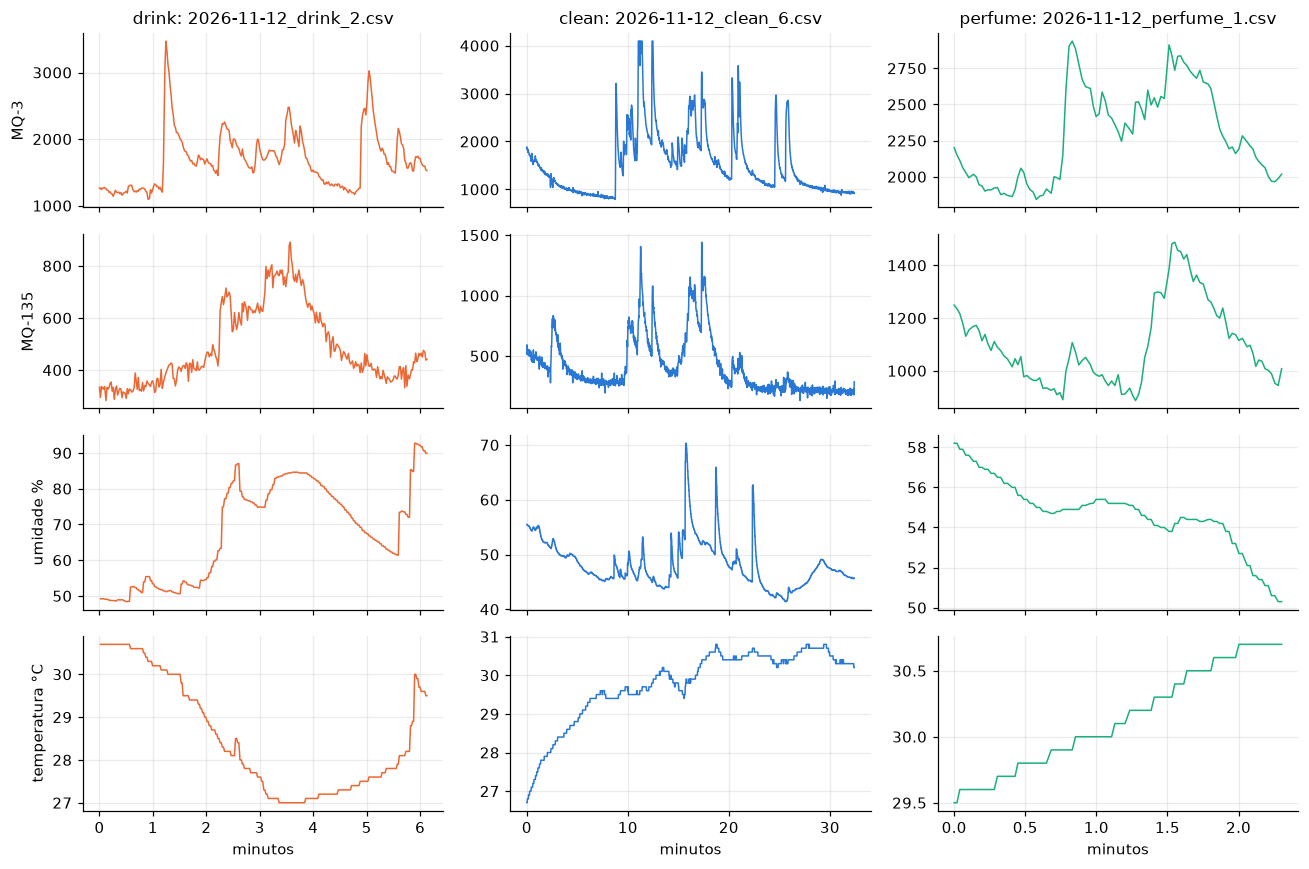

In [9]:
exemplos = {"drink": "2026-11-12_equipe_drink_2.csv", "clean": "2026-11-12_equipe_clean_6.csv", "perfume": "2026-11-12_equipe_perfume_1.csv"}
sensores = [("mq3_raw", "MQ-3"), ("mq135_raw", "MQ-135"), ("humidity_pct", "umidade %"), ("temperature_c", "temperatura °C")]
fig, eixos = plt.subplots(len(sensores), len(exemplos), figsize=(12, 8), sharex="col")
for j, (caso, sessao) in enumerate(exemplos.items()):
    s = leituras[leituras["session_file"] == sessao]
    minutos = (s["t_ms"] - s["t_ms"].min()) / 60000
    for i, (coluna, nome) in enumerate(sensores):
        eixos[i, j].plot(minutos, s[coluna], color=COR_CASO[caso], linewidth=1)
        if j == 0:
            eixos[i, j].set_ylabel(nome)
    eixos[0, j].set_title(f"{caso}: {sessao.replace('_equipe', '')}")
    eixos[-1, j].set_xlabel("minutos")
salvar(fig, "03_sessoes_exemplo")
plt.show()

Trios com duração > 5 s (amostras não consecutivas no tempo): 2 de 209; maior: 66 s
session_file
2026-11-12_equipe_drink_1.csv    2
Tentativas por curva:
 caso     tipo  
clean    avulsa    300
         sopro      11
drink    sopro     196
perfume  avulsa    102


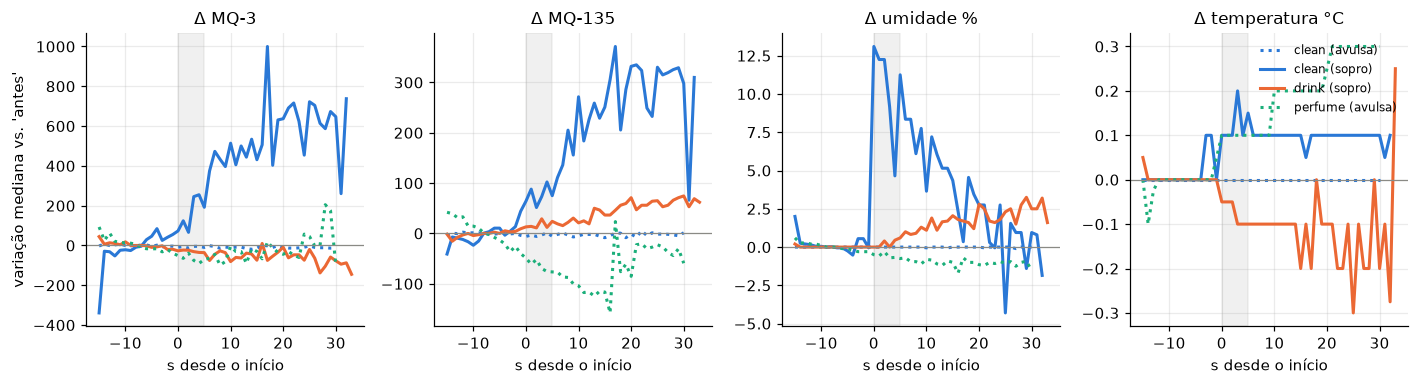

In [10]:
# Curvas alinhadas: só tentativas que o recorte marcou como sopro (3 amostras), mais uma amostra
# das linhas avulsas de cada caso para servir de comparação.
rng = np.random.default_rng(42)
tentativas["duracao_s"] = tentativas["blow_end_s"] - tentativas["blow_start_s"]
sopros = tentativas[tentativas["tipo"] == "sopro (3 amostras)"]
longos = sopros[sopros["duracao_s"] > 5]
print(f"Trios com duração > 5 s (amostras não consecutivas no tempo): {len(longos)} de {len(sopros)}; "
      f"maior: {sopros['duracao_s'].max():.0f} s")
print(longos.groupby("session_file").size().to_string())
# Só trios dentro da duração padrão de sopro (5 s), para a curva não misturar janelas de tamanhos diferentes.
sopros_ids = set(sopros.loc[sopros["duracao_s"] <= 5, "attempt_id"])
avulsas = tentativas[tentativas["tipo"] == "amostra avulsa"]
avulsas_ids = set(avulsas.groupby("caso", group_keys=False).apply(
    lambda g: g.sample(min(len(g), 300), random_state=42))["attempt_id"])
alinhado = fases[fases["attempt_id"].isin(sopros_ids | avulsas_ids)].copy()
alinhado["t_rel_s"] = ((alinhado["t_ms"] - alinhado["blow_start_ms"]) / 1000).round()
alinhado["tipo"] = np.where(alinhado["attempt_id"].isin(sopros_ids), "sopro", "avulsa")
for coluna in ["mq3_raw", "mq135_raw", "humidity_pct", "temperature_c"]:
    base = alinhado[alinhado["phase"] == "before"].groupby("attempt_id")[coluna].median()
    alinhado[f"d_{coluna}"] = alinhado[coluna] - alinhado["attempt_id"].map(base)

grupos = alinhado.groupby(["caso", "tipo"])["attempt_id"].nunique()
print("Tentativas por curva:\n", grupos.to_string())

fig, eixos = plt.subplots(1, 4, figsize=(13, 3.6), sharex=True)
for eixo, (coluna, nome) in zip(eixos, sensores):
    for (caso, tipo), g in alinhado.groupby(["caso", "tipo"]):
        curva = g.groupby("t_rel_s")[f"d_{coluna}"].median()
        eixo.plot(curva.index, curva.values, color=COR_CASO[caso], linewidth=2,
                  linestyle="-" if tipo == "sopro" else ":", label=f"{caso} ({tipo})")
    eixo.axvspan(0, 5, color="#8a8a85", alpha=0.12)
    eixo.axhline(0, color="#8a8a85", linewidth=0.8)
    eixo.set_title(f"Δ {nome}")
    eixo.set_xlabel("s desde o início")
eixos[0].set_ylabel("variação mediana vs. 'antes'")
eixos[-1].legend(frameon=False, fontsize=8, loc="upper right")
salvar(fig, "03_curvas_alinhadas")
plt.show()

Tabela de padrões. Para descrever (não para decidir), um sensor "subiu" quando a subida
(`*_rise`, pico menos a mediana do "antes") passa de um corte fixo: 10% do valor do "antes" para
o MQ-3 e o MQ-135, e 5 pontos percentuais para a umidade. Os cortes são escolhas desta análise
descritiva, não limiares do sistema.

In [11]:
CORTE_RELATIVO_MQ = 0.10
CORTE_UMIDADE_PP = 5.0
padrao = pd.DataFrame({
    "mq3": dataset["mq3_rise"] > CORTE_RELATIVO_MQ * dataset["mq3_before"],
    "mq135": dataset["mq135_rise"] > CORTE_RELATIVO_MQ * dataset["mq135_before"],
    "umidade": dataset["humidity_rise"] > CORTE_UMIDADE_PP,
})
nomes = {
    (False, False, False): "nada sobe",
    (True, False, False): "só MQ-3",
    (True, True, False): "MQ-3 + MQ-135",
    (True, True, True): "MQ-3 + MQ-135 + umidade",
}
dataset["padrao_29_10"] = [nomes.get(tuple(l), "outro") for l in padrao.itertuples(index=False)]
tabela_padrao = pd.crosstab([dataset["caso"], dataset["tipo"]], dataset["padrao_29_10"], normalize="index").round(3) * 100
display(tabela_padrao)

padrao_29_10                MQ-3 + MQ-135  MQ-3 + MQ-135 + umidade  nada sobe  outro  só MQ-3
caso    tipo                                                                                 
clean   amostra avulsa               69.9                      0.9        6.9   21.0      1.3
        sopro (3 amostras)           36.4                     27.3        0.0   36.4      0.0
drink   sopro (3 amostras)           22.2                     29.4       13.4   30.4      4.6
perfume amostra avulsa               38.0                      0.0       43.0    6.0     13.0

**Veredito — seção 3:** **não confirmado como regra, e com dados insuficientes.** Só cerca de
29% das tentativas de bebida mostram os três sensores subindo (tabela acima); 22% mostram só
MQ-3 + MQ-135 e 13% não mostram subida nenhuma pelos cortes usados. Há dois motivos que a equipe deve
pesar. (1) A umidade das sessões de bebida já está alta *antes* do sopro (mediana do "antes" em
≈81%), então a subida durante o sopro é pequena: o sinal de hábito está no *nível*, e não na
subida. (2) O pico de uma janela de 45 s sobre um sensor ruidoso marca "subiu" mesmo em ar parado:
cerca de 70% das amostras `clean` caem em "MQ-3 + MQ-135". Além disso, quase todo `sem_efeito`
do lote é ar parado: só 11 trios de `clean` passam de 60% de umidade. Falta o caso que testaria a
hipótese de verdade: **sopro de quem não bebeu**. O padrão "só MQ-3" (vapor no ambiente) também
não pode ser avaliado, porque não há sessão de álcool 70% no lote.

> **[EQUIPE: interpretar]** _Texto da equipe. Os números acima são a base; o agente não escreve a interpretação._

## 4. A umidade separa as classes sozinha? (20/10 e 05/11)

Em 20/10 a equipe viu a umidade subir quando se sopra no DHT11 e quase não mudar com o copo de
álcool. Em 05/11 concluiu que o melhor modelo seria uma **árvore de decisão com a umidade no
primeiro nó**. Aqui:

1. a área sob a curva ROC (AUC) de cada feature sozinha (0,5 = não separa; 1,0 = separa tudo);
2. uma árvore de um nó só, com uma feature de umidade, avaliada deixando uma sessão de fora por vez
   (`LeaveOneGroupOut`, porque há um só participante);
3. uma árvore rasa com todas as features: qual feature ela escolhe para o primeiro nó e a
   importância de cada uma.

Os números abaixo são **exploratórios**: não são o desempenho do modelo. O experimento oficial é
o `train` (validação cruzada aninhada por grupo).

,AUC,"separação |AUC-0,5|",grupo
humidity_peak,0.998,0.498,dht11
humidity_before,0.994,0.494,dht11
mq135_peak,0.967,0.467,mq135
mq135_before,0.966,0.466,mq135
mq3_before,0.953,0.453,mq3
mq3_peak,0.948,0.448,mq3
humidity_rise,0.819,0.319,dht11
mq3_recovery_s,0.765,0.265,mq3
humidity_peak_time_s,0.725,0.225,dht11
mq135_mq3_rise_ratio,0.287,0.213,mq135


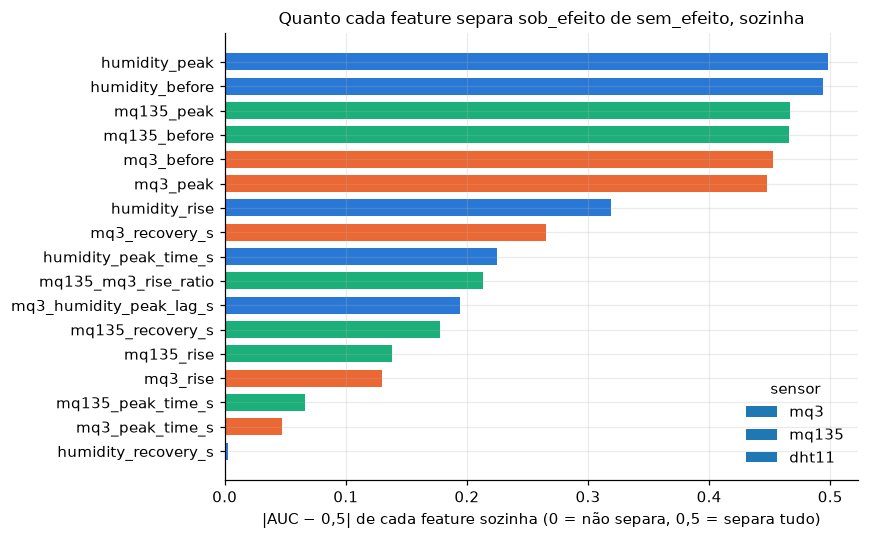

In [12]:
from sklearn.impute import SimpleImputer
from sklearn.metrics import balanced_accuracy_score, recall_score, roc_auc_score
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, export_text

y = (dataset["target"] == "sob_efeito").astype(int)
grupos_sessao = dataset["session_file"]

auc = {}
for coluna in all_feature_columns():
    x = dataset[coluna]
    ok = x.notna()
    if y[ok].nunique() == 2:
        auc[coluna] = roc_auc_score(y[ok], x[ok])
auc = pd.Series(auc, name="AUC").to_frame()
auc["separação |AUC-0,5|"] = (auc["AUC"] - 0.5).abs()
auc["grupo"] = [next(g for g, cols in SENSOR_GROUPS.items() if c in cols) for c in auc.index]
auc = auc.sort_values("separação |AUC-0,5|", ascending=False).round(3)
display(auc)

fig, eixo = plt.subplots(figsize=(8, 5))
cores_grupo = {"mq3": "#eb6834", "mq135": "#1baf7a", "dht11": "#2a78d6"}
eixo.barh(auc.index[::-1], auc["separação |AUC-0,5|"][::-1], color=auc["grupo"][::-1].map(cores_grupo), height=0.7)
for g, cor in cores_grupo.items():
    eixo.barh([], [], color=cor, label=g)
eixo.legend(frameon=False, loc="lower right", title="sensor")
eixo.set_xlabel("|AUC − 0,5| de cada feature sozinha (0 = não separa, 0,5 = separa tudo)")
eixo.set_title("Quanto cada feature separa sob_efeito de sem_efeito, sozinha")
salvar(fig, "04_auc_por_feature")
plt.show()

In [13]:
def avaliar(colunas: list[str], profundidade: int) -> dict:
    """Árvore com class_weight balanceado, uma sessão de fora por vez; previsões juntadas no fim."""
    modelo = Pipeline([
        ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("clf", DecisionTreeClassifier(max_depth=profundidade, class_weight="balanced", random_state=42)),
    ])
    previsto = cross_val_predict(modelo, dataset[colunas], y, groups=grupos_sessao, cv=LeaveOneGroupOut())
    return {
        "features": ", ".join(colunas) if len(colunas) <= 2 else f"{len(colunas)} features",
        "profundidade": profundidade,
        "acurácia balanceada": balanced_accuracy_score(y, previsto),
        "recall sob_efeito": recall_score(y, previsto, pos_label=1),
        "recall sem_efeito": recall_score(y, previsto, pos_label=0),
    }

comparacao = pd.DataFrame([
    avaliar(["humidity_peak"], 1),
    avaliar(["humidity_rise"], 1),
    avaliar(["mq3_rise"], 1),
    avaliar(SENSOR_GROUPS["dht11"], 3),
    avaliar(all_feature_columns(), 3),
]).round(3)
display(comparacao)

arvore = Pipeline([
    ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
    ("clf", DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=42)),
]).fit(dataset[all_feature_columns()], y)
clf = arvore.named_steps["clf"]
print("Árvore rasa treinada com todo o lote (só para ver a estrutura):\n")
print(export_text(clf, feature_names=all_feature_columns(), decimals=1))
importancia = pd.Series(clf.feature_importances_, index=all_feature_columns()).sort_values(ascending=False)
display(importancia[importancia > 0].round(3).to_frame("importância (Gini)"))

,features,profundidade,acurácia balanceada,recall sob_efeito,recall sem_efeito
0,humidity_peak,1,0.986,1.000,0.971
1,humidity_rise,1,0.828,0.732,0.925
2,mq3_rise,1,0.736,0.541,0.932
3,6 features,3,0.971,0.954,0.988
4,17 features,3,0.903,0.835,0.971


Árvore rasa treinada com todo o lote (só para ver a estrutura):

|--- humidity_peak <= 54.1
|   |--- class: 0
|--- humidity_peak >  54.1
|   |--- humidity_peak <= 66.4
|   |   |--- mq135_before <= 414.5
|   |   |   |--- class: 1
|   |   |--- mq135_before >  414.5
|   |   |   |--- class: 0
|   |--- humidity_peak >  66.4
|   |   |--- humidity_peak <= 71.9
|   |   |   |--- class: 1
|   |   |--- humidity_peak >  71.9
|   |   |   |--- class: 1



,importância (Gini)
humidity_peak,0.971
mq135_before,0.029


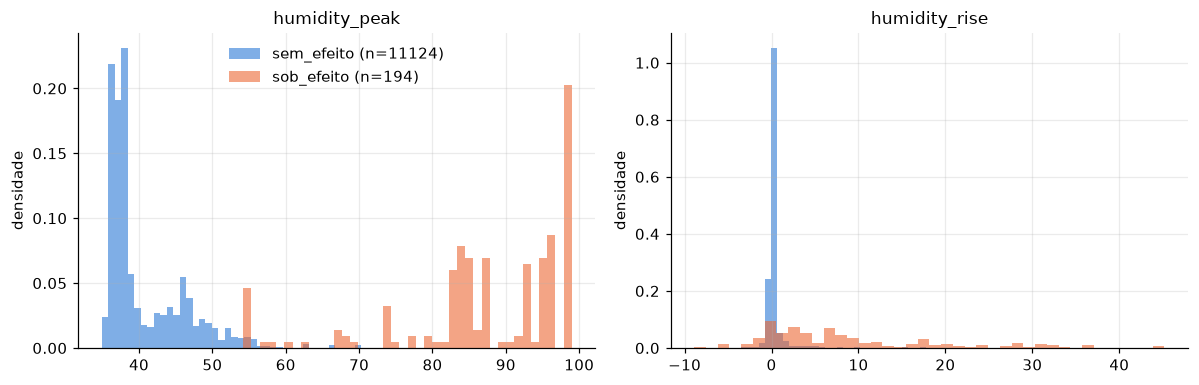

Umidade de pico por caso e tipo (mediana e quartis):


count   25%   50%   75%
caso    tipo                                         
clean   amostra avulsa      11013.0  36.8  37.9  43.7
        sopro (3 amostras)     11.0  63.3  65.3  68.8
drink   sopro (3 amostras)    194.0  83.6  88.0  96.4
perfume amostra avulsa        100.0  54.4  55.2  55.4

In [14]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 3.6))
for eixo, coluna in zip(eixos, ["humidity_peak", "humidity_rise"]):
    for classe, cor in COR_CLASSE.items():
        valores = dataset.loc[dataset["target"] == classe, coluna].dropna()
        eixo.hist(valores, bins=40, color=cor, alpha=0.6, density=True, label=f"{classe} (n={len(valores)})")
    eixo.set_title(coluna)
    eixo.set_ylabel("densidade")
eixos[0].legend(frameon=False)
salvar(fig, "04_umidade_por_classe")
plt.show()

print("Umidade de pico por caso e tipo (mediana e quartis):")
display(dataset.groupby(["caso", "tipo"])["humidity_peak"].describe()[["count", "25%", "50%", "75%"]].round(1))

**Veredito — seção 4:** **confirmado nos dados atuais, mas com uma explicação que não serve
para o carro.** A umidade separa as classes quase sozinha (AUC e árvore de um nó acima), e a
árvore rasa coloca `humidity_peak` no primeiro nó (corte ≈54%), com importância de ≈97%. O
motivo, porém, é o desenho da coleta: quase todo `sem_efeito` é ar parado e todo `sob_efeito` é
sopro. A umidade aqui separa **"soprou (ou estava em sala úmida)" de "não soprou"**, e não
"bebeu" de "não bebeu". Dois sinais disso: `humidity_before`, medida *antes* do sopro, já tem AUC
de 0,99 (as sessões de bebida foram em ambiente mais úmido), e a mediana da umidade do perfume
(≈55%) fica a ~1 ponto do corte da árvore. Um motorista sóbrio também sopra úmido. A árvore com
todas as 17 features ficou pior que a de uma feature (acurácia balanceada 0,90 contra 0,99). Com
4 sessões de bebida e 1 participante, isso é uma estimativa exploratória e frágil. Para testar a
ideia de 05/11 faltam sopros sem álcool.

> **[EQUIPE: interpretar]** _Texto da equipe. Os números acima são a base; o agente não escreve a interpretação._

## 5. Perfume, bebida com e sem gelo, boca aberta × sopro (12/11)

O diário de 12/11 registra:

- perfume borrifado perto do sensor: o MQ-3 não passou de **0,8 PPM**, e o MQ-135 ficou entre
  **1200 e 1500** no ápice;
- bebida com gelo deu leituras menos expressivas que sem gelo;
- expirar com a boca aberta variou mais que soprar na direção do sensor.

,arquivo,no_lote,ppm_max (firmware),"% leituras com ppm > 0,8",mq135_raw mín,mq135_raw p95,mq135_raw máx,mq135_mv máx
0,leituras_25_perfume.csv,True,0.8,0.0,887.0,1422.15,1488.0,1362
1,leituras_perfume.csv,False,0.7,0.0,854.0,1288.30,1535.0,1429


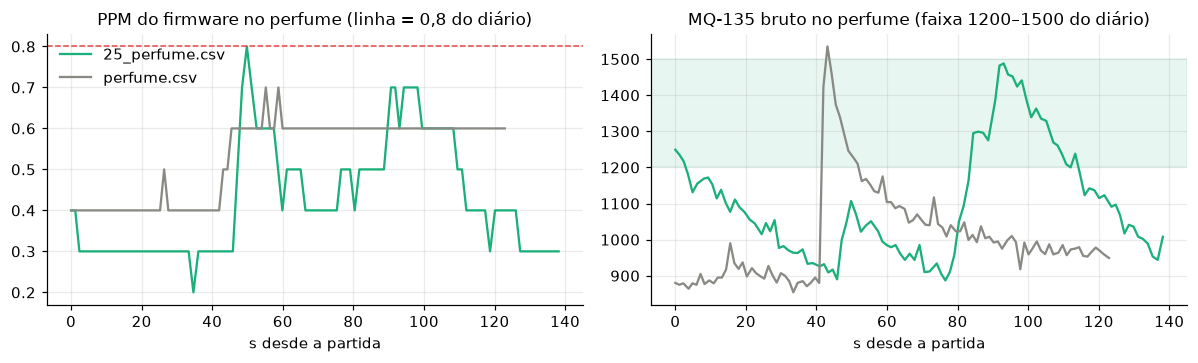

In [15]:
perfumes = ["leituras_25_perfume.csv", "leituras_perfume.csv"]
linhas_perfume = []
for nome in perfumes:
    df = leituras_brutas[nome]
    linhas_perfume.append({
        "arquivo": nome,
        "no_lote": nome in por_origem.index,
        "ppm_max (firmware)": df["ppm"].max(),
        "% leituras com ppm > 0,8": round((df["ppm"] > 0.8).mean() * 100, 1),
        "mq135_raw mín": df["mq135_raw"].min(),
        "mq135_raw p95": df["mq135_raw"].quantile(0.95),
        "mq135_raw máx": df["mq135_raw"].max(),
        "mq135_mv máx": df["mq135_mv"].max(),
    })
display(pd.DataFrame(linhas_perfume))

fig, eixos = plt.subplots(1, 2, figsize=(11, 3.4), sharex=True)
for nome in perfumes:
    df = leituras_brutas[nome]
    seg = (df["t_ms"] - df["t_ms"].min()) / 1000
    eixos[0].plot(seg, df["ppm"], linewidth=1.5, label=nome.replace("leituras_", ""),
                  color="#1baf7a" if nome in por_origem.index else "#8a8a85")
    eixos[1].plot(seg, df["mq135_raw"], linewidth=1.5, color="#1baf7a" if nome in por_origem.index else "#8a8a85")
eixos[0].axhline(0.8, color="#e34948", linestyle="--", linewidth=1)
eixos[0].set_title("PPM do firmware no perfume (linha = 0,8 do diário)")
eixos[1].axhspan(1200, 1500, color="#1baf7a", alpha=0.1)
eixos[1].set_title("MQ-135 bruto no perfume (faixa 1200–1500 do diário)")
for eixo in eixos:
    eixo.set_xlabel("s desde a partida")
eixos[0].legend(frameon=False)
salvar(fig, "05_perfume")
plt.show()

In [16]:
# Gelo e boca aberta: procurar o registro nas anotações das tentativas e nos nomes dos arquivos.
termos = ["gelo", "ice", "boca", "aberta", "mouth_open"]
anotacoes = tentativas["notes"].fillna("").str.lower()
nos_nomes = [a for a in inventario["arquivo"] if any(t in a.lower() for t in termos)]
print("Tentativas com gelo/boca aberta anotados:", int(anotacoes.str.contains("|".join(termos)).sum()))
print("Arquivos com esses termos no nome:", nos_nomes)

Tentativas com gelo/boca aberta anotados: 0
Arquivos com esses termos no nome: []


**Veredito — seção 5:**

- **Perfume, MQ-3 abaixo de 0,8 PPM:** **confirmado** nos dois arquivos de perfume: o PPM do
  firmware chega a 0,8 e não passa disso (tabela acima).
- **Perfume, MQ-135 entre 1200 e 1500:** **confirmado** no arquivo do lote (máximo dentro da faixa);
  o arquivo fora do lote passa um pouco de 1500 no pico.
- **Gelo × sem gelo** e **boca aberta × sopro:** **dados insuficientes.** Nada disso foi
  registrado por tentativa (nem nas anotações nem nos nomes). Para analisar, a coleta precisa
  anotar `notes` (ou um caso próprio) em cada sopro.

Atenção: o MQ-135 do perfume (mínimo ≈890, pico ≈1490) é em geral mais alto que o das sessões de
bebida (mediana do pico por tentativa ≈890), mas há bebida chegando a ≈1300 e o perfume do lote é
um arquivo só, de um dia só. Isso não basta para dizer que o MQ-135 separa perfume de bebida.

> **[EQUIPE: interpretar]** _Texto da equipe. Os números acima são a base; o agente não escreve a interpretação._

## 6. A temperatura não difere entre as classes? (12/11)

Em 12/11 a equipe passou a desconsiderar a temperatura, porque ela não variava de forma clara
entre ar ambiente e hálito. Por isso `features.py` deixa a temperatura de fora. Aqui comparamos
o nível da temperatura e a variação dela em cada tentativa (pico menos a mediana do "antes").

temp_antes  temp_subida
target     tipo                                       
sem_efeito amostra avulsa            29.4          0.0
           sopro (3 amostras)        29.8          0.1
sob_efeito sopro (3 amostras)        29.4          0.2

AUC temp_antes: 0.439 | AUC temp_subida: 0.627
Mesmo dia (12/11) e só sopros de 3 amostras:


target             sem_efeito  sob_efeito
temp_antes  count       11.00      194.00
            mean        30.02       29.06
            std          0.48        1.15
            min         29.50       27.00
            25%         29.70       28.12
            50%         29.80       29.40
            75%         30.60       30.00
            max         30.60       31.10
temp_subida count       11.00      194.00
            mean         0.19        0.48
            std          0.12        0.80
            min          0.10       -1.50
            25%          0.10       -0.10
            50%          0.10        0.20
            75%          0.25        1.17
            max          0.40        2.40

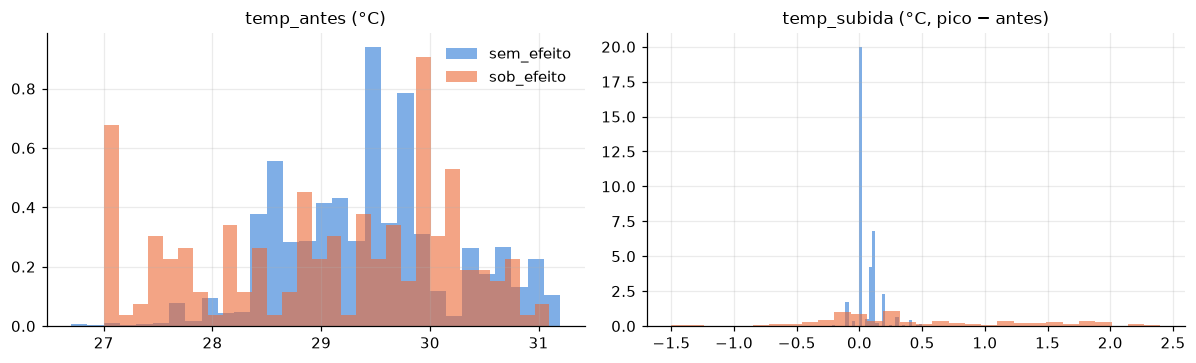

In [17]:
antes_temp = fases[fases["phase"] == "before"].groupby("attempt_id")["temperature_c"].median()
pico_temp = fases[fases["phase"].isin(["blow", "after"])].groupby("attempt_id")["temperature_c"].max()
temp = pd.DataFrame({"temp_antes": antes_temp, "temp_subida": pico_temp - antes_temp}).reset_index()
temp = temp.merge(dataset[["attempt_id", "target", "caso", "dia", "tipo"]], on="attempt_id")

display(temp.groupby(["target", "tipo"])[["temp_antes", "temp_subida"]].median().round(2))
ok = temp.dropna(subset=["temp_antes", "temp_subida"])
yt = (ok["target"] == "sob_efeito").astype(int)
print(f"AUC temp_antes: {roc_auc_score(yt, ok['temp_antes']):.3f} | AUC temp_subida: {roc_auc_score(yt, ok['temp_subida']):.3f}")
print("Mesmo dia (12/11) e só sopros de 3 amostras:")
mesmo_dia = ok[(ok["dia"] == "2026-11-12") & (ok["tipo"] == "sopro (3 amostras)")]
display(mesmo_dia.groupby("target")[["temp_antes", "temp_subida"]].describe().round(2).T)

fig, eixos = plt.subplots(1, 2, figsize=(11, 3.4))
for eixo, coluna in zip(eixos, ["temp_antes", "temp_subida"]):
    for classe, cor in COR_CLASSE.items():
        eixo.hist(ok.loc[ok["target"] == classe, coluna], bins=30, color=cor, alpha=0.6, density=True, label=classe)
    eixo.set_title(coluna + (" (°C)" if coluna == "temp_antes" else " (°C, pico − antes)"))
eixos[0].legend(frameon=False)
salvar(fig, "06_temperatura")
plt.show()

**Veredito — seção 6:** **confirmado, com ressalva de dados insuficientes.** As medianas da
temperatura de antes são iguais entre as classes (≈29,4 °C) e o AUC do nível é 0,44, ou seja, não
separa. A subida durante o sopro tem AUC de 0,63 (mediana de 0,2 °C contra 0,1 °C): é fraca e
fica dentro do ruído do DHT11. A comparação mais justa, no mesmo dia e só entre sopros, tem
apenas 11 tentativas `sem_efeito` contra 194 `sob_efeito`; é pouco para afirmar. A temperatura
continua **fora das features**, também porque cada sessão tem a temperatura do dia em que foi
coletada.

> **[EQUIPE: interpretar]** _Texto da equipe. Os números acima são a base; o agente não escreve a interpretação._

## 7. Distribuição das features e correlação

Distribuição de cada feature por classe e correlação de Spearman (por postos, que aguenta
valores extremos e relações não lineares).

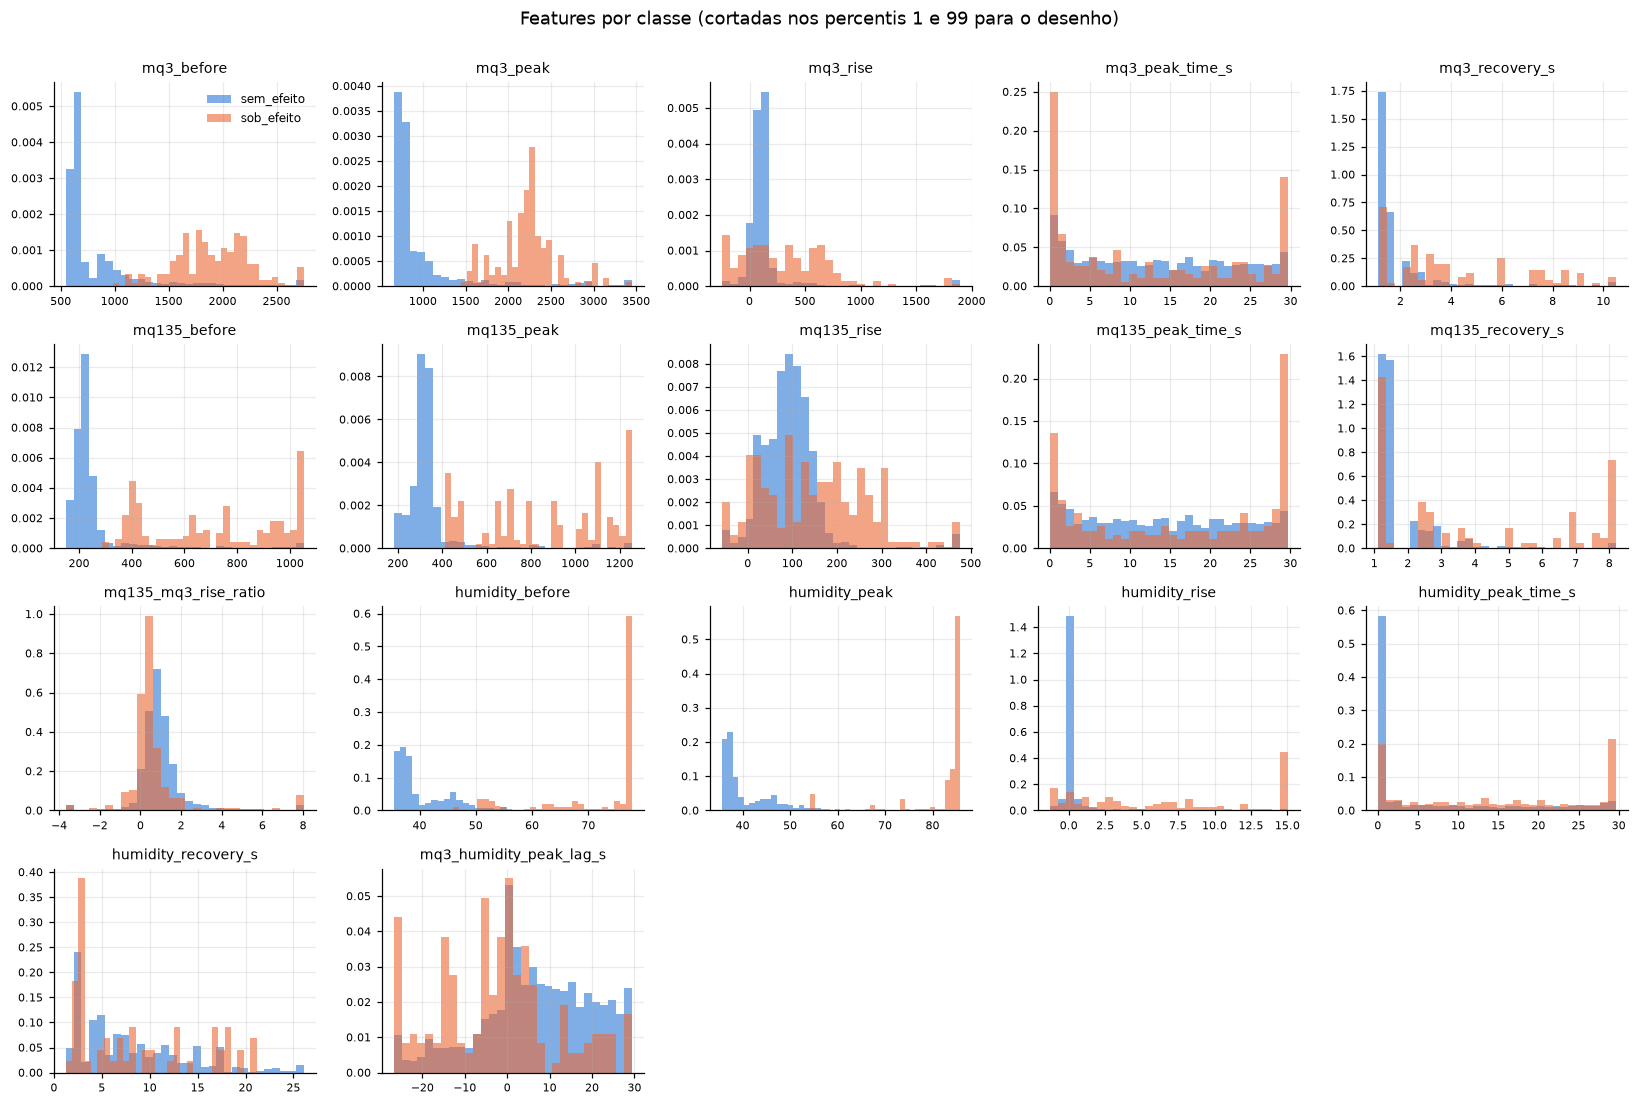

target,sem_efeito,sob_efeito
mq3_before,656.00,1891.00
mq3_peak,770.00,2210.00
mq3_rise,105.50,263.50
mq3_peak_time_s,12.80,8.69
mq3_recovery_s,1.40,3.15
mq135_before,220.50,724.50
mq135_peak,321.00,891.00
mq135_rise,91.00,146.00
mq135_peak_time_s,13.47,17.48
mq135_recovery_s,1.40,2.73


In [18]:
colunas = all_feature_columns()
fig, eixos = plt.subplots(4, 5, figsize=(15, 10))
for eixo, coluna in zip(eixos.flat, colunas):
    for classe, cor in COR_CLASSE.items():
        valores = dataset.loc[dataset["target"] == classe, coluna].dropna()
        if valores.empty:
            continue
        limites = dataset[coluna].quantile([0.01, 0.99]).values
        eixo.hist(valores.clip(*limites), bins=30, color=cor, alpha=0.6, density=True, label=classe)
    eixo.set_title(coluna, fontsize=9)
    eixo.tick_params(labelsize=7)
for eixo in list(eixos.flat)[len(colunas):]:
    eixo.axis("off")
eixos[0, 0].legend(frameon=False, fontsize=8)
fig.suptitle("Features por classe (cortadas nos percentis 1 e 99 para o desenho)", y=1.0)
salvar(fig, "07_distribuicao_features")
plt.show()

display(dataset.groupby("target")[colunas].median().T.round(2))

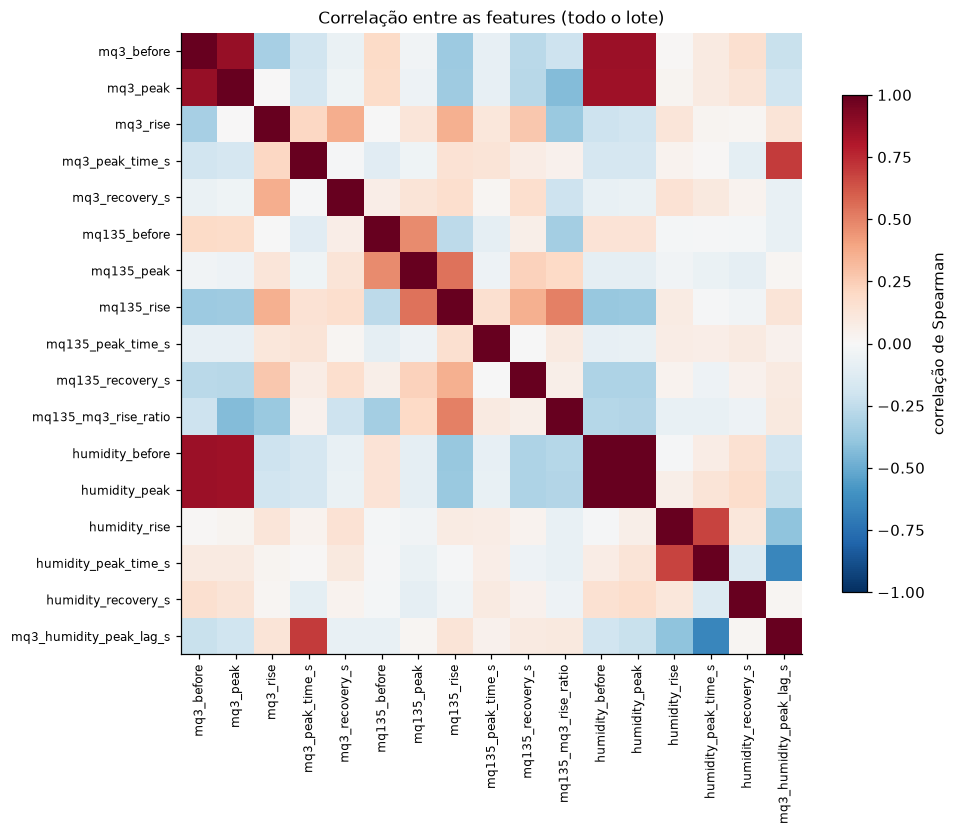

Pares com |correlação| ≥ 0,9:


,,spearman
humidity_before,humidity_peak,0.995


In [19]:
correlacao = dataset[colunas].corr(method="spearman")
fig, eixo = plt.subplots(figsize=(9, 7.5))
imagem = eixo.imshow(correlacao, cmap="RdBu_r", vmin=-1, vmax=1)
eixo.set_xticks(range(len(colunas)), colunas, rotation=90, fontsize=8)
eixo.set_yticks(range(len(colunas)), colunas, fontsize=8)
eixo.grid(False)
fig.colorbar(imagem, ax=eixo, shrink=0.8, label="correlação de Spearman")
eixo.set_title("Correlação entre as features (todo o lote)")
salvar(fig, "07_correlacao")
plt.show()

pares = correlacao.where(np.triu(np.ones(correlacao.shape, dtype=bool), k=1)).stack()
print("Pares com |correlação| ≥ 0,9:")
display(pares[pares.abs() >= 0.9].sort_values(key=abs, ascending=False).round(3).to_frame("spearman"))

**Veredito — seção 7:** o único par com |correlação| ≥ 0,9 é `humidity_before` × `humidity_peak`
(0,995): como a umidade quase não sobe, o pico é o valor de antes. Algumas features têm cauda
longa (a razão `mq135_mq3_rise_ratio` divide por subidas perto de zero e chega a 231 no máximo).
Correlação alta não atrapalha árvores, mas pesa na regressão logística e na leitura da
importância das features. Para a equipe: manter as duas de umidade é redundante.

> **[EQUIPE: interpretar]** _Texto da equipe. Os números acima são a base; o agente não escreve a interpretação._

## 8. Decisões de preparação

A preparação que o pipeline já faz está em `src/` e `src/train.py` (`model_specs`). A tabela
diz o que é feito, por quê, e o que esta análise sugere revisar. Itens marcados
**[EQUIPE: decidir]** mudam o dataset e não foram aplicados.

In [20]:
resumo = {
    "tentativas": len(dataset),
    "sob_efeito": int((dataset["target"] == "sob_efeito").sum()),
    "sem_efeito": int((dataset["target"] == "sem_efeito").sum()),
    "proporção sob_efeito": round((dataset["target"] == "sob_efeito").mean(), 4),
    "sessões": dataset["session_file"].nunique(),
    "participantes": dataset["participant_id"].nunique(),
    "tentativas descartadas no recorte": len(tentativas) - len(dataset),
    "trios de bebida com PPM < 0,6 descartados": sum(int(a.split("; ")[1].split()[0]) for a in avisos if "trios de fora" in a),
    "features com algum vazio": int(dataset[colunas].isna().any().sum()),
}
display(pd.Series(resumo).to_frame("valor"))
print("Avisos do recorte (assign_phases), primeiros 140 caracteres de cada:")
for aviso in avisos_fase:
    print(" -", aviso[:140])

,valor
tentativas,11325.0000
sob_efeito,194.0000
sem_efeito,11131.0000
proporção sob_efeito,0.0171
sessões,12.0000
participantes,1.0000
tentativas descartadas no recorte,89.0000
"trios de bebida com PPM < 0,6 descartados",44.0000
features com algum vazio,9.0000


Avisos do recorte (assign_phases), primeiros 140 caracteres de cada:
 - tentativas sem leituras antes ou durante o sopro (confira blow_start_s): ['2026-11-12_equipe_clean_6_s1', '2026-11-12_equipe_clean_6_s112', 
 - 2026-11-12_equipe_clean_6.csv: tentativas muito próximas (o 'antes' pega o sopro anterior): ['2026-11-12_equipe_clean_6_s2', '2026-11-12_equ
 - 2026-11-12_equipe_clean_7.csv: tentativas muito próximas (o 'antes' pega o sopro anterior): ['2026-11-12_equipe_clean_7_s2', '2026-11-12_equ
 - 2026-11-12_equipe_drink_1.csv: tentativas muito próximas (o 'antes' pega o sopro anterior): ['2026-11-12_equipe_drink_1_s2', '2026-11-12_equ
 - 2026-11-12_equipe_drink_2.csv: tentativas muito próximas (o 'antes' pega o sopro anterior): ['2026-11-12_equipe_drink_2_s2', '2026-11-12_equ
 - 2026-11-12_equipe_drink_3.csv: tentativas muito próximas (o 'antes' pega o sopro anterior): ['2026-11-12_equipe_drink_3_s2', '2026-11-12_equ
 - 2026-11-12_equipe_drink_4.csv: tentativas muito próximas (o 'ant

| Etapa | O que o pipeline faz hoje | Justificativa | O que a EDA sugere |
| --- | --- | --- | --- |
| **Limpeza de arquivos** | Só os 12 arquivos do lote; `instavel` no nome fica de fora; CSV de sessão nunca é editado | Dados reais da equipe, rastreáveis até o arquivo do firmware | Manter fora `leituras_novos_acima_08.csv` (recorte, não sessão) e `leituras_20_sensor_Instavel.csv` |
| **Linhas inválidas** | `validate_readings` exige `t_ms` e `mq3_raw`; tentativa sem MQ-3 antes ou no sopro é descartada | Sem "antes" não há subida para comparar | Ok |
| **Aquecimento do MQ-3** | Não tratado | — | **[EQUIPE: decidir]** descartar os primeiros minutos de cada sessão (seção 1 mostra o MQ-3 alto no início) |
| **Sessões antigas (10/11)** | Não tratado | — | **[EQUIPE: decidir]** `DECISAO_SESSOES_ANTIGAS` (seção 2) |
| **Seleção dos sopros de bebida** | Trio sai se algum PPM < 0,6 | O arquivo é de bebida, mas nem toda amostra pegou o sopro | Cuidado: o PPM vem do próprio MQ-3. Escolher os trios pelo PPM deixa os `sob_efeito` com MQ-3 alto **por construção**, o que infla a separação do MQ-3 |
| **Trios longos** | O trio usa 3 amostras consecutivas *da lista*, não do tempo | Há lacunas nos CSVs de bebida | Alguns trios cobrem mais de 5 s (e até ~66 s); a célula da seção 3 conta quantos. **[EQUIPE: decidir]** descartar trios com duração acima do padrão |
| **Janelas sobrepostas** | Avisa quando o "antes" de uma tentativa pega a anterior | — | O recorte emitiu os avisos de sobreposição listados na célula abaixo: tentativas coladas fazem o "antes" pegar a anterior, e `*_before` e `*_rise` ficam contaminados. **[EQUIPE: decidir]** se o recorte por trio e por amostra continua |
| **Ausentes** | `SimpleImputer(strategy="median")` dentro do `Pipeline`, ajustado só no treino | DHT11 vazio no começo; `*_recovery_s` vazio quando o sensor não voltou | Ok. Para `*_recovery_s`, o vazio tem significado ("não recuperou"); um indicador de ausência pode ajudar |
| **Normalização** | `StandardScaler` só na regressão logística; árvores e Random Forest sem escala | A logística depende da escala; árvores não | Ok. MQ-3 (0–4095), MQ-135 e umidade (%) têm escalas muito diferentes (seção 7) |
| **Encoding** | Nenhuma feature categórica; o alvo fica como texto (`sob_efeito`/`sem_efeito`) | O scikit-learn aceita rótulo em texto | `caso`, `dia` e `periodo` são só metadados de análise, nunca features |
| **Desbalanceamento** | `class_weight="balanced"`; métricas F1 macro, acurácia balanceada e recall de `sob_efeito` | Acurácia simples premiaria "sempre `sem_efeito`" | Uma sessão de ambiente domina o dataset. **[EQUIPE: decidir]** limitar amostras avulsas por sessão |
| **Separação treino/teste** | Por participante; com um participante só, usar `--group-by session_file` | Sopros da mesma sessão não podem ficar dos dois lados | Com 4 sessões de bebida, cada dobra tem pouquíssimos grupos `sob_efeito` |
| **Temperatura** | Fora das features | Diário de 12/11 | Confirmado como confundidor de dia (seção 6) |

**Próximas coletas sugeridas por esta análise** (para a equipe avaliar):

1. sopros **sem álcool** (`clean` com sopro, `mouthwash`), para a umidade deixar de separar só "soprou";
2. sessões de `alcohol70_hands`/`alcohol70_spray`, para testar o padrão "só MQ-3 sobe";
3. anotar em `notes` gelo/sem gelo e boca aberta/sopro em cada tentativa;
4. mais de um participante, com `participant_id` próprio;
5. marcar `sopro_inicio`/`sopro_fim` na coleta, em vez de recortar trios pelo PPM.

> **[EQUIPE: interpretar]** _Texto da equipe. Os números acima são a base; o agente não escreve a interpretação._

In [21]:
shutil.rmtree(pasta_tmp, ignore_errors=True)
print("Figuras em", FIGURAS.relative_to(REPO))
print(*sorted(p.name for p in FIGURAS.glob("*.png")), sep="\n")

Figuras em ml/reports/figuras_eda
01_ambiente_fim_de_semana.png
01_volume_e_ausentes.png
02_mq3_por_esquema.png
03_curvas_alinhadas.png
03_sessoes_exemplo.png
04_auc_por_feature.png
04_umidade_por_classe.png
05_perfume.png
06_temperatura.png
07_correlacao.png
07_distribuicao_features.png
